# VisDrone MOT test-dev | 3 detector trên cùng 6 frame

**Mục tiêu:** với **một sequence/video MOT test-dev**, chọn **6 frame** và xuất **6 ảnh, mỗi ảnh là một lưới 1×4:**

`Ground Truth | YOLO11m (fine-tuned) | Faster R-CNN (fine-tuned) | RF-DETR (fine-tuned)`

- **Không train lại**, không tính mAP; đây là phần **đánh giá định tính**.
- GT và ảnh lấy từ dataset [VisDrone MOT+DET converted](https://www.kaggle.com/datasets/tiendq/visdrone-mot-det-converted), dùng COCO `test-dev.json` do `prepare.py` sinh ra.
- **Faster R-CNN**: dùng đúng `src.training.frcnn_colab.make_model()` của repo, khôi phục checkpoint `best.pt` theo `src/training/frcnn_colab.py`.
- **RF-DETR**: dùng đúng API checkpoint trong `src/inference/visualize_rfdetr.py`: `RFDETRMedium(pretrain_weights=..., num_classes=10, resolution=576)`; nhãn dự đoán `0–9` cộng `1` để thành VisDrone `1–10`.
- **YOLO11m**: đọc `best.pt`, nhãn dự đoán `0–9` cộng `1`.
- Chạy **tuần tự từng model**, giải phóng GPU khi chuyển model để hạn chế hết VRAM trên Kaggle T4.

## 1. Cấu hình — chỉ chỉnh cell này khi cần

In [36]:
from pathlib import Path

INPUT = Path('/kaggle/input')
WORK = Path('/kaggle/working')

# Converted dataset
DATASET_ROOT = Path('/kaggle/input/datasets/tiendq/visdrone-mot-det-converted/uav_tracking_mot_det')

YOLO_CHECKPOINT = Path('/kaggle/input/models/tiendq/checkpoint-det/pytorch/default/1/best_yolo11m.pt')
FRCNN_CHECKPOINT = Path('/kaggle/input/models/tiendq/checkpoint-det/pytorch/default/1/best_frcnn.pt')
RFDETR_CHECKPOINT = Path('/kaggle/input/models/tiendq/checkpoint-det/pytorch/default/1/best_ema.pth')

# V0 = sequence thứ 0 khi sort tên; có thể đặt trực tiếp SEQ_NAME='uav...'
SEQ_NAME = None
SEQ_INDEX = 0
FRAME_IDS = None                # ví dụ [1, 50, 100, 150, 200, 250]; None -> chọn 6 frame cách đều
N_FRAMES = 6

# Inference và cách hiển thị
SCORE_THRESH = 0.25             # cùng ngưỡng hiển thị cho 3 model (không hiệu chỉnh score)
YOLO_IMGSZ = 640
FRCNN_MIN_SIZE = 800
FRCNN_MAX_SIZE = 1333
RFDETR_MODEL = 'RFDETRMedium'
RFDETR_RESOLUTION = 576
PANEL_WIDTH = 920               # lưới 4 cột có chiều rộng ~3700 px
SHOW_CLASS_IDS = True           # in mã lớp 1..10 cạnh hộp; legend bên dưới
SHOW_SCORES = True             # bật True nếu muốn kèm confidence
SHOW_IGNORED_GT = False         # vẽ vùng ignored màu xám trong cột GT

OUTPUT = WORK / 'compare_3_detectors_mot_testdev'
REPO_DIR = WORK / 'uav-tracking-visual'
REPO_URL = 'https://github.com/ntrThanh/uav-tracking.git'
REPO_SHA = '7a23f4c4f0af306e497391f32f2c04f441958a98'

assert N_FRAMES == 6, 'Bài này được thiết kế xuất đúng 6 frame.'
assert 0.0 <= SCORE_THRESH < 1.0
WORK.mkdir(parents=True, exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=True)
print('Inputs:', [p.name for p in sorted(INPUT.iterdir())] if INPUT.exists() else 'Kaggle Input chưa sẵn sàng')

Inputs: ['datasets', 'models']


## 2. Cài đúng phiên bản thư viện, lấy code gốc từ repo

In [37]:
%pip -q install "ultralytics==8.4.197" "rfdetr==1.11.2" "Pillow>=9"

Note: you may need to restart the kernel to use updated packages.


In [38]:
import os, sys, json, csv, gc, math, time, hashlib, subprocess, platform
from collections import defaultdict
import numpy as np
import torch
import torchvision
import ultralytics
import rfdetr
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

assert torch.cuda.is_available(), 'Hãy bật GPU trong Kaggle Settings -> Accelerator.'
DEVICE = 'cuda:0'
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('Ultralytics:', ultralytics.__version__)

if not (REPO_DIR / '.git').is_dir():
    subprocess.run(['git', 'clone', '--quiet', REPO_URL, str(REPO_DIR)], check=True)
subprocess.run(['git', '-C', str(REPO_DIR), 'fetch', '--quiet', 'origin', REPO_SHA], check=True)
subprocess.run(['git', '-C', str(REPO_DIR), 'checkout', '--quiet', '--detach', REPO_SHA], check=True)
actual_sha = subprocess.check_output(['git', '-C', str(REPO_DIR), 'rev-parse', 'HEAD'], text=True).strip()
assert actual_sha == REPO_SHA, (actual_sha, REPO_SHA)
sys.path.insert(0, str(REPO_DIR))
from src.training.frcnn_colab import make_model as make_repo_frcnn_model
print('Source FRCNN:', REPO_DIR / 'src/training/frcnn_colab.py')
print('Source RF-DETR:', REPO_DIR / 'src/inference/visualize_rfdetr.py')
print('Repo SHA:', actual_sha)

GPU: Tesla T4
PyTorch: 2.11.0+cu130 | torchvision: 0.26.0+cu130
Ultralytics: 8.4.197
Source FRCNN: /kaggle/working/uav-tracking-visual/src/training/frcnn_colab.py
Source RF-DETR: /kaggle/working/uav-tracking-visual/src/inference/visualize_rfdetr.py
Repo SHA: 7a23f4c4f0af306e497391f32f2c04f441958a98


## 3. Tìm đúng dataset + ba checkpoint trong Kaggle Input

In [39]:
def find_dataset_root(hint: Path) -> Path:
    if (hint / 'data/processed/coco/test-dev.json').is_file() and (hint / 'data/raw').is_dir():
        return hint
    matches = []
    for ds in sorted(INPUT.iterdir()):
        if not ds.is_dir():
            continue
        for candidate in (ds, ds / 'uav_tracking_mot_det'):
            if (candidate / 'data/processed/coco/test-dev.json').is_file() and (candidate / 'data/raw').is_dir():
                matches.append(candidate)
    if len(matches) != 1:
        raise FileNotFoundError(
            'Không xác định được converted dataset đã giải nén. Tìm thấy: '
            + str(matches) + '\nHãy chỉnh DATASET_ROOT cho đúng thư mục chứa data/raw và data/processed.'
        )
    return matches[0]

DATASET_ROOT = find_dataset_root(DATASET_ROOT)
print('Dataset root:', DATASET_ROOT)

# Chỉ scan các dataset checkpoint, không rglob qua hàng chục nghìn ảnh converted dataset.
checkpoint_ds = [d for d in sorted(INPUT.iterdir()) if d.is_dir() and d != DATASET_ROOT and d != DATASET_ROOT.parent]
found = {}
for ds in checkpoint_ds:
    for filename in ('best.pt', 'checkpoint_best_total.pth'):
        found.setdefault(filename, []).extend(p for p in ds.rglob(filename) if p.is_file())

print('Checkpoint candidates:')
for k, ps in found.items():
    for p in ps:
        print(' ', k, '->', p)

def resolve_checkpoint(configured, filename: str, hints: tuple[str, ...]) -> Path:
    if configured is not None:
        selected = Path(configured)
        if not selected.is_file():
            raise FileNotFoundError(f'Checkpoint tự cấu hình không tồn tại: {selected}')
        return selected
    options = sorted(set(found.get(filename, [])))
    options_with_hints = [p for p in options if any(x in str(p).lower() for x in hints)]
    if len(options_with_hints) == 1:
        return options_with_hints[0]
    if len(options) == 1:
        return options[0]
    raise FileNotFoundError(
        f'Không phân biệt được {filename}: {options}.\n'
        'Hãy đặt YOLO_CHECKPOINT / FRCNN_CHECKPOINT / RFDETR_CHECKPOINT bằng Path(...) trong cell cấu hình.'
    )

YOLO_CHECKPOINT = resolve_checkpoint(YOLO_CHECKPOINT, 'best.pt', ('yolo', 't1_'))
FRCNN_CHECKPOINT = resolve_checkpoint(FRCNN_CHECKPOINT, 'best.pt', ('frcnn', 'faster', 't2_'))
RFDETR_CHECKPOINT = resolve_checkpoint(RFDETR_CHECKPOINT, 'checkpoint_best_total.pth', ('rfdetr', 'rf-detr', 't3'))
assert YOLO_CHECKPOINT != FRCNN_CHECKPOINT, 'YOLO và Faster R-CNN đang trỏ vào cùng một file!'
print('\nYOLO  :', YOLO_CHECKPOINT)
print('FRCNN :', FRCNN_CHECKPOINT)
print('RFDETR:', RFDETR_CHECKPOINT)

Dataset root: /kaggle/input/datasets/tiendq/visdrone-mot-det-converted/uav_tracking_mot_det
Checkpoint candidates:

YOLO  : /kaggle/input/models/tiendq/checkpoint-det/pytorch/default/1/best_yolo11m.pt
FRCNN : /kaggle/input/models/tiendq/checkpoint-det/pytorch/default/1/best_frcnn.pt
RFDETR: /kaggle/input/models/tiendq/checkpoint-det/pytorch/default/1/best_ema.pth


## 4. Chọn 6 frame từ **cùng một video MOT test-dev**

Sử dụng `data/processed/coco/test-dev.json`, do `prepare.py` tạo: `images[].seq`, `images[].frame`, `images[].file_name` và `annotations[].category_id` **1–10**. Do đó GT khớp quy tắc tiền xử lý của nhóm (bỏ class 0/11, clip box). Nguồn ảnh gốc: `data/raw/<file_name>`.

In [40]:
COCO_PATH = DATASET_ROOT / 'data/processed/coco/test-dev.json'
RAW_DIR = DATASET_ROOT / 'data/raw'
coco = json.loads(COCO_PATH.read_text(encoding='utf-8'))
CLASS_NAMES = {
    1: 'pedestrian', 2: 'people', 3: 'bicycle', 4: 'car', 5: 'van',
    6: 'truck', 7: 'tricycle', 8: 'awning-tricycle', 9: 'bus', 10: 'motor'
}
COLOR_HEX = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
             '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']

assert sorted(int(cat['id']) for cat in coco['categories']) == list(range(1, 11))
seq_to_images = defaultdict(list)
for im in coco['images']:
    assert im.get('source') == 'mot', 'Tập này phải là MOT test-dev'
    assert im.get('seq') is not None and im.get('frame') is not None, 'Thiếu seq/frame từ converter của repo'
    seq_to_images[str(im['seq'])].append(im)
seq_names = sorted(seq_to_images)
print('Các video MOT test-dev (index -> tên):')
for i, name in enumerate(seq_names):
    print(f'  V{i:02d}  {name:35s} {len(seq_to_images[name]):4d} frames')

if SEQ_NAME is None:
    assert 0 <= SEQ_INDEX < len(seq_names), f'SEQ_INDEX phải thuộc [0, {len(seq_names)-1}]'
    SELECTED_SEQ = seq_names[SEQ_INDEX]
else:
    SELECTED_SEQ = str(SEQ_NAME)
    assert SELECTED_SEQ in seq_to_images, f'Không thấy {SELECTED_SEQ}; dùng danh sách trên.'

all_records = sorted(seq_to_images[SELECTED_SEQ], key=lambda r: int(r['frame']))
assert len(all_records) >= N_FRAMES
if FRAME_IDS is None:
    inds = np.linspace(0, len(all_records)-1, N_FRAMES, dtype=int).tolist()
    selected = [all_records[i] for i in inds]
else:
    assert len(FRAME_IDS) == N_FRAMES and len(set(FRAME_IDS)) == N_FRAMES
    id_to_record = {int(r['frame']): r for r in all_records}
    missing = set(FRAME_IDS) - set(id_to_record)
    assert not missing, f'FRAME_IDS không có trong video: {missing}'
    selected = [id_to_record[i] for i in FRAME_IDS]

GT_BY_IMAGE = defaultdict(list)
for a in coco['annotations']:
    GT_BY_IMAGE[int(a['image_id'])].append(a)
IGNORED_BY_IMAGE = defaultdict(list)
for a in coco.get('ignored_regions', []):
    IGNORED_BY_IMAGE[int(a['image_id'])].append(a)

image_paths = []
for im in selected:
    path = RAW_DIR / im['file_name']
    assert path.is_file(), f'Thiếu ảnh gốc: {path}'
    image_paths.append(path)

print('\nVIDEO:', SELECTED_SEQ, '| số frame:', len(all_records))
for im, p in zip(selected, image_paths):
    print(f"  frame {int(im['frame']):6d}: {p.name} | GT boxes={len(GT_BY_IMAGE[int(im['id'])])}")

Các video MOT test-dev (index -> tên):
  V00  uav0000009_03358_v                   219 frames
  V01  uav0000073_00600_v                   328 frames
  V02  uav0000073_04464_v                   312 frames
  V03  uav0000077_00720_v                   780 frames
  V04  uav0000088_00290_v                   296 frames
  V05  uav0000119_02301_v                   179 frames
  V06  uav0000120_04775_v                  1000 frames
  V07  uav0000161_00000_v                   308 frames
  V08  uav0000188_00000_v                   260 frames
  V09  uav0000201_00000_v                   677 frames
  V10  uav0000249_00001_v                   360 frames
  V11  uav0000249_02688_v                   244 frames
  V12  uav0000297_00000_v                   146 frames
  V13  uav0000297_02761_v                   373 frames
  V14  uav0000306_00230_v                   420 frames
  V15  uav0000355_00001_v                   468 frames
  V16  uav0000370_00001_v                   265 frames

VIDEO: uav0000009_03358_v

## 5. Inference YOLO11m, rồi giải phóng GPU

Theo repo YOLO 10 lớp VisDrone: class nội bộ `0..9`; cộng 1 khi xuất để đúng mã lớp `1..10`. `max_det=1000` như quy ước của nhóm.

In [41]:
def normalized_detection(xyxy, cls_id, score):
    assert 1 <= int(cls_id) <= 10, f'Sai mã lớp VisDrone {cls_id}'
    return {'bbox': [float(x) for x in xyxy], 'cls': int(cls_id), 'score': float(score)}

all_predictions = {'YOLO11m': {}, 'Faster R-CNN': {}, 'RF-DETR': {}}

from ultralytics import YOLO
yolo_model = YOLO(str(YOLO_CHECKPOINT))
yolo_names = {int(k): str(v) for k, v in yolo_model.names.items()} if isinstance(yolo_model.names, dict) else dict(enumerate(yolo_model.names))
assert len(yolo_names) == 10, f'YOLO checkpoint phải được fine-tune trên 10 lớp, nhưng có: {yolo_names}'
for k in range(10):
    assert yolo_names[k].lower().strip() == CLASS_NAMES[k+1], (k, yolo_names[k], CLASS_NAMES[k+1])

for im, path in zip(selected, image_paths):
    r = yolo_model.predict(
        source=str(path), imgsz=YOLO_IMGSZ, conf=SCORE_THRESH,
        iou=0.7, max_det=1000, device=0, verbose=False, save=False
    )[0]
    dets = []
    if r.boxes is not None:
        coords = r.boxes.xyxy.cpu().numpy()
        classes = r.boxes.cls.int().cpu().numpy()
        scores = r.boxes.conf.cpu().numpy()
        for box, cls0, sc in zip(coords, classes, scores):
            dets.append(normalized_detection(box, int(cls0)+1, sc))
    all_predictions['YOLO11m'][int(im['id'])] = dets
    print('YOLO   ', im['frame'], ':', len(dets), 'boxes')

del yolo_model
gc.collect()
torch.cuda.empty_cache()

YOLO    1 : 21 boxes
YOLO    44 : 22 boxes
YOLO    88 : 72 boxes
YOLO    131 : 135 boxes
YOLO    175 : 88 boxes
YOLO    219 : 81 boxes


## 6. Inference Faster R-CNN theo **hàm `make_model()` trong repo**

Dùng đúng `src.training.frcnn_colab.make_model(cfg, pretrained=False)` với `FasterRCNN R50-FPN v2`, predictor **11 lớp gồm background**, score threshold nội bộ 0.05, NMS 0.5 và tối đa 1000 box/ảnh. Khôi phục `checkpoint['model']`; nhãn của Faster R-CNN đã là VisDrone `1..10` nên **không cộng 1**.

In [42]:
import torch
import gc
from torch.torch_version import TorchVersion
from torchvision.transforms.functional import to_tensor
from src.training.frcnn_colab import make_model

# 1. Load checkpoint
with torch.serialization.safe_globals([TorchVersion]):
    frcnn_payload = torch.load(
        FRCNN_CHECKPOINT,
        map_location="cpu",
        weights_only=True,
    )

# 2. Lấy trọng số và cấu hình training
if "model" in frcnn_payload:
    frcnn_weights = frcnn_payload["model"]
    saved_cfg = frcnn_payload.get("config", {})
    checkpoint_epoch = frcnn_payload.get("epoch")
else:
    frcnn_weights = frcnn_payload
    saved_cfg = {}
    checkpoint_epoch = None

# 3. Kiểm tra kiến trúc và số lớp
assert "roi_heads.box_predictor.cls_score.weight" in frcnn_weights
assert frcnn_weights["roi_heads.box_predictor.cls_score.weight"].shape[0] == 11

# 4. Lấy đúng cấu hình từ checkpoint
frcnn_cfg = {
    "min_size": int(saved_cfg.get("min_size", FRCNN_MIN_SIZE)),
    "max_size": int(saved_cfg.get("max_size", FRCNN_MAX_SIZE)),
}

# 5. Khởi tạo model MỘT LẦN và nạp trọng số
frcnn_model = make_model(frcnn_cfg, pretrained=False)
frcnn_model.load_state_dict(frcnn_weights, strict=True)
frcnn_model = frcnn_model.to(DEVICE).eval()

print("Faster R-CNN loaded successfully!")
print("Config:", frcnn_cfg)
print("Checkpoint epoch (zero-based):", checkpoint_epoch)
print("Device:", DEVICE)

# Giải phóng bộ nhớ CPU
del frcnn_weights, frcnn_payload

# 6. Inference trên đúng 6 frame đã chọn
with torch.inference_mode():
    for im, path in zip(selected, image_paths):
        with Image.open(path) as pic:
            x = to_tensor(pic.convert("RGB")).to(DEVICE)

        pred = frcnn_model([x])[0]

        boxes = pred["boxes"].cpu().numpy()
        classes = pred["labels"].cpu().numpy().astype(int)
        scores = pred["scores"].cpu().numpy()

        dets = [
            normalized_detection(box, cl, sc)
            for box, cl, sc in zip(boxes, classes, scores)
            if sc >= SCORE_THRESH and 1 <= cl <= 10
        ]

        all_predictions["Faster R-CNN"][int(im["id"])] = dets

        print("FRCNN", im["frame"], ":", len(dets), "boxes")

        del x, pred

# 7. Giải phóng GPU trước khi load RF-DETR
del frcnn_model
gc.collect()
torch.cuda.empty_cache()

print("Faster R-CNN inference completed!")

/usr/local/lib/python3.13/dist-packages/torchvision/models/detection/backbone_utils.py:162: UserWarning: Changing trainable_backbone_layers has no effect if neither pretrained nor pretrained_backbone have been set to True, falling back to trainable_backbone_layers=5 so that all layers are trainable
  warnings.warn(


Faster R-CNN loaded successfully!
Config: {'min_size': 800, 'max_size': 1333}
Checkpoint epoch (zero-based): 16
Device: cuda:0
FRCNN 1 : 22 boxes
FRCNN 44 : 25 boxes
FRCNN 88 : 71 boxes
FRCNN 131 : 122 boxes
FRCNN 175 : 86 boxes
FRCNN 219 : 82 boxes
Faster R-CNN inference completed!


## 7. Inference RF-DETR theo **`visualize_rfdetr.py` trong repo**

```python
model = RFDETRMedium(pretrain_weights='checkpoint_best_total.pth', num_classes=10, resolution=576)
detections = model.predict(image, threshold=SCORE_THRESH)
```

`detections.xyxy`, `.confidence`, `.class_id`; **class_id 0..9 ⇒ cộng 1**. Nếu checkpoint khác Medium/576, chỉnh `RFDETR_MODEL` và `RFDETR_RESOLUTION` cho đúng run.

In [43]:
from rfdetr import RFDETRMedium
RFDETR_CLASS = getattr(rfdetr, RFDETR_MODEL)
rfdetr_model = RFDETR_CLASS(
    pretrain_weights=str(RFDETR_CHECKPOINT),
    num_classes=len(CLASS_NAMES),
    resolution=RFDETR_RESOLUTION,
)
for im, path in zip(selected, image_paths):
    with Image.open(path) as pic:
        rgb = pic.convert('RGB')
    pred = rfdetr_model.predict(rgb, threshold=SCORE_THRESH)
    dets = [normalized_detection(box, int(cl)+1, sc)
            for box, cl, sc in zip(pred.xyxy, pred.class_id, pred.confidence)]
    all_predictions['RF-DETR'][int(im['id'])] = dets
    print('RF-DETR', im['frame'], ':', len(dets), 'boxes')

del rfdetr_model
gc.collect()
torch.cuda.empty_cache()

[2026-11-04 15:11:24] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-11-04 15:11:24] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-11-04 15:11:24] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


RF-DETR 1 : 21 boxes
RF-DETR 44 : 18 boxes
RF-DETR 88 : 67 boxes
RF-DETR 131 : 109 boxes
RF-DETR 175 : 97 boxes
RF-DETR 219 : 104 boxes


## 8. Ghép **6 hình 1×4** và lưu JPG

Mỗi hình gồm 4 cột trên cùng **một ảnh gốc**, dùng **cùng màu cho 10 lớp**. GT lấy từ `coco/test-dev.json` (đã làm sạch theo repo), không phải nhãn tự dự đoán. Legend lớp phía dưới. Việc hiển thị cùng ngưỡng confidence chỉ phục vụ trực quan; **không phải so sánh mAP chuẩn**.

In [44]:
def load_font(size):
    for p in ('/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',
              '/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf'):
        try:
            return ImageFont.truetype(p, size)
        except OSError:
            pass
    return ImageFont.load_default()

TITLE_FONT = load_font(21)
BOX_FONT = load_font(14)
LEGEND_FONT = load_font(17)


def bbox_xyxy_from_coco(a):
    x, y, w, h = a['bbox']
    return [float(x), float(y), float(x+w), float(y+h)]


def make_panel(image, detections, title, ignored=None):
    scale = PANEL_WIDTH / image.width
    h = max(1, round(image.height * scale))
    panel = image.resize((PANEL_WIDTH, h), Image.Resampling.LANCZOS)
    d = ImageDraw.Draw(panel)
    for det in detections:
        b = det['bbox']
        x1, y1, x2, y2 = [float(v)*scale for v in b]
        x1 = max(0, min(PANEL_WIDTH-1, x1))
        x2 = max(0, min(PANEL_WIDTH-1, x2))
        y1 = max(0, min(h-1, y1))
        y2 = max(0, min(h-1, y2))
        if x2 <= x1 or y2 <= y1:
            continue
        cls = int(det['cls'])
        color = COLOR_HEX[cls-1]
        d.rectangle((x1, y1, x2, y2), outline=color, width=2)
        if SHOW_CLASS_IDS:
            label = str(cls)
            if SHOW_SCORES and det.get('score') is not None:
                label += f" {det['score']:.2f}"
            x0, y0 = int(x1), int(y1)
            label_w = max(15, int(d.textlength(label, font=BOX_FONT))+6)
            label_h = 17
            label_y = y0 if y0 < label_h else y0-label_h
            d.rectangle((x0, label_y, min(PANEL_WIDTH-1, x0+label_w), label_y+label_h), fill=color)
            d.text((x0+3, label_y), label, fill='white', font=BOX_FONT)
    if ignored and SHOW_IGNORED_GT:
        for a in ignored:
            x1, y1, x2, y2 = [v*scale for v in bbox_xyxy_from_coco(a)]
            d.rectangle((x1, y1, x2, y2), outline='#aaaaaa', width=2)
    title_h = 40
    framed = Image.new('RGB', (PANEL_WIDTH, h+title_h), 'white')
    framed.paste(panel, (0, title_h))
    fd = ImageDraw.Draw(framed)
    fd.rectangle((0, 0, PANEL_WIDTH, title_h-1), fill='#162033')
    fd.text((12, 8), f'{title}  |  {len(detections)} boxes', font=TITLE_FONT, fill='white')
    return framed


def make_legend(total_w, context):
    bar_h = 76
    bar = Image.new('RGB', (total_w, bar_h), '#ffffff')
    d = ImageDraw.Draw(bar)
    d.text((14, 8), context, fill='#222222', font=LEGEND_FONT)
    x = 14
    for c, name in CLASS_NAMES.items():
        label = f'{c} {name}'
        width = int(d.textlength(label, font=LEGEND_FONT))+34
        if x+width > total_w-15:
            raise RuntimeError('PANEL_WIDTH quá nhỏ để hiển thị legend; hãy tăng PANEL_WIDTH')
        d.rectangle((x, 45, x+14, 59), fill=COLOR_HEX[c-1])
        d.text((x+20, 42), label, fill='#202020', font=LEGEND_FONT)
        x += width
    return bar

# Clean up ONLY this experiment output folder before recreating the six figures.
# Running this cell again is safe: old images/metadata are replaced, not mixed.
import shutil
expected_output = (WORK / 'compare_3_detectors_mot_testdev').resolve()
assert OUTPUT.resolve() == expected_output, f'Unsafe output cleanup path: {OUTPUT}'
if OUTPUT.exists():
    shutil.rmtree(OUTPUT)
OUTPUT.mkdir(parents=True, exist_ok=True)
print(f'Cleaned experiment output: {OUTPUT}')

GAP = 8
TOTAL_W = 4*PANEL_WIDTH + 3*GAP
rows = []
for idx, (im, path) in enumerate(zip(selected, image_paths), start=1):
    with Image.open(path) as src_image:
        image = src_image.convert('RGB')
    image_id = int(im['id'])
    gt = [{'bbox': bbox_xyxy_from_coco(a), 'cls': int(a['category_id']), 'score': None}
          for a in GT_BY_IMAGE[image_id]]
    panels = [
        make_panel(image, gt, 'GROUND TRUTH', IGNORED_BY_IMAGE[image_id]),
        make_panel(image, all_predictions['YOLO11m'][image_id], 'YOLO11m'),
        make_panel(image, all_predictions['Faster R-CNN'][image_id], 'Faster R-CNN'),
        make_panel(image, all_predictions['RF-DETR'][image_id], 'RF-DETR'),
    ]
    assert len(set(p.size for p in panels)) == 1
    panel_h = panels[0].height
    context = f"MOT test-dev | sequence {SELECTED_SEQ} | frame #{int(im['frame'])} | score threshold: {SCORE_THRESH:.2f}"
    legend = make_legend(TOTAL_W, context)
    grid = Image.new('RGB', (TOTAL_W, panel_h+legend.height), 'white')
    for col, panel in enumerate(panels):
        grid.paste(panel, (col*(PANEL_WIDTH+GAP), 0))
    grid.paste(legend, (0, panel_h))
    filename = f"comparison_{idx:02d}_{SELECTED_SEQ}_frame{int(im['frame']):07d}.jpg"
    output_path = OUTPUT / filename
    grid.save(output_path, quality=93, optimize=True)
    rows.append({
        'image': filename,
        'sequence': SELECTED_SEQ,
        'frame_id': int(im['frame']),
        'image_file': im['file_name'],
        'n_gt': len(gt),
        'n_yolo': len(all_predictions['YOLO11m'][image_id]),
        'n_frcnn': len(all_predictions['Faster R-CNN'][image_id]),
        'n_rfdetr': len(all_predictions['RF-DETR'][image_id]),
        'n_ignored': len(IGNORED_BY_IMAGE[image_id]),
    })
    print(f"[{idx}/6] {output_path.name} | GT {len(gt)}, YOLO {rows[-1]['n_yolo']}, "
          f"FRCNN {rows[-1]['n_frcnn']}, RFDETR {rows[-1]['n_rfdetr']}")
    image.close()
    for panel in panels: panel.close()
    grid.close()

Cleaned experiment output: /kaggle/working/compare_3_detectors_mot_testdev
[1/6] comparison_01_uav0000009_03358_v_frame0000001.jpg | GT 17, YOLO 21, FRCNN 22, RFDETR 21
[2/6] comparison_02_uav0000009_03358_v_frame0000044.jpg | GT 20, YOLO 22, FRCNN 25, RFDETR 18
[3/6] comparison_03_uav0000009_03358_v_frame0000088.jpg | GT 59, YOLO 72, FRCNN 71, RFDETR 67
[4/6] comparison_04_uav0000009_03358_v_frame0000131.jpg | GT 90, YOLO 135, FRCNN 122, RFDETR 109
[5/6] comparison_05_uav0000009_03358_v_frame0000175.jpg | GT 81, YOLO 88, FRCNN 86, RFDETR 97
[6/6] comparison_06_uav0000009_03358_v_frame0000219.jpg | GT 67, YOLO 81, FRCNN 82, RFDETR 104


## 9. Lưu metadata và kiểm tra output sạch

Chỉ giữ **6 ảnh JPG**, `counts_per_frame.csv` và `summary.json` trong một thư mục.
Không tạo ZIP; nếu còn ZIP của phiên bản notebook cũ, cell này chỉ xóa đúng ZIP đó.
Để tái lập chính xác, metadata vẫn ghi commit repo, checkpoint SHA-256 và thông số inference.

In [45]:
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(8*1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

summary = {
    'experiment': 'qualitative_3_detectors_same_frames',
    'split': 'VisDrone2019-MOT-test-dev',
    'sequence': SELECTED_SEQ,
    'sequence_index': seq_names.index(SELECTED_SEQ),
    'frame_ids': [int(im['frame']) for im in selected],
    'dataset_source': 'https://www.kaggle.com/datasets/tiendq/visdrone-mot-det-converted',
    'gt_source': 'data/processed/coco/test-dev.json, repo prepare.py',
    'repo': REPO_URL,
    'repo_commit': actual_sha,
    'checkpoints': {
        'yolo': {'path': str(YOLO_CHECKPOINT), 'sha256': sha256_file(YOLO_CHECKPOINT)},
        'frcnn': {'path': str(FRCNN_CHECKPOINT), 'sha256': sha256_file(FRCNN_CHECKPOINT)},
        'rfdetr': {'path': str(RFDETR_CHECKPOINT), 'sha256': sha256_file(RFDETR_CHECKPOINT)},
    },
    'inference': {'score_thresh': SCORE_THRESH, 'yolo_imgsz': YOLO_IMGSZ,
                  'frcnn_min_size': frcnn_cfg['min_size'], 'frcnn_max_size': frcnn_cfg['max_size'],
                  'rfdetr_model': RFDETR_MODEL, 'rfdetr_resolution': RFDETR_RESOLUTION,
                  'max_det_yolo': 1000, 'max_det_frcnn': 1000, 'max_det_rfdetr': 300,
                  'note': 'Qualitative visualization; detection counts are not mAP scores'},
    'versions': {'python': platform.python_version(), 'torch': torch.__version__,
                 'torchvision': torchvision.__version__, 'ultralytics': ultralytics.__version__,
                 'rfdetr': getattr(rfdetr, '__version__', '1.11.2')},
    'frames': rows,
}
(OUTPUT/'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
with open(OUTPUT/'counts_per_frame.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)
# Remove a ZIP left by older notebook versions; this run intentionally keeps files unzipped.
stale_zip = WORK / 'compare_3_detectors_mot_testdev.zip'
if stale_zip.exists():
    stale_zip.unlink()
    print(f'Removed old ZIP: {stale_zip.name}')

expected_files = {row['image'] for row in rows} | {'summary.json', 'counts_per_frame.csv'}
actual_files = {p.name for p in OUTPUT.iterdir() if p.is_file()}
assert len(rows) == N_FRAMES == 6, f'Unexpected row count: {len(rows)}'
assert actual_files == expected_files, (sorted(actual_files - expected_files), sorted(expected_files - actual_files))
assert all(p.is_file() for p in OUTPUT.iterdir()), 'Unexpected subdirectory in output'
print(f'Output ready: {OUTPUT} ({len(actual_files)} files: 6 JPG + CSV + JSON)')
print('No ZIP created. Save the notebook version in Kaggle to preserve the output folder.')

Removed old ZIP: compare_3_detectors_mot_testdev.zip
Output ready: /kaggle/working/compare_3_detectors_mot_testdev (8 files: 6 JPG + CSV + JSON)
No ZIP created. Save the notebook version in Kaggle to preserve the output folder.


## 10. Preview các ảnh đã xuất

Full resolution: (3704, 634) | file: comparison_01_uav0000009_03358_v_frame0000001.jpg


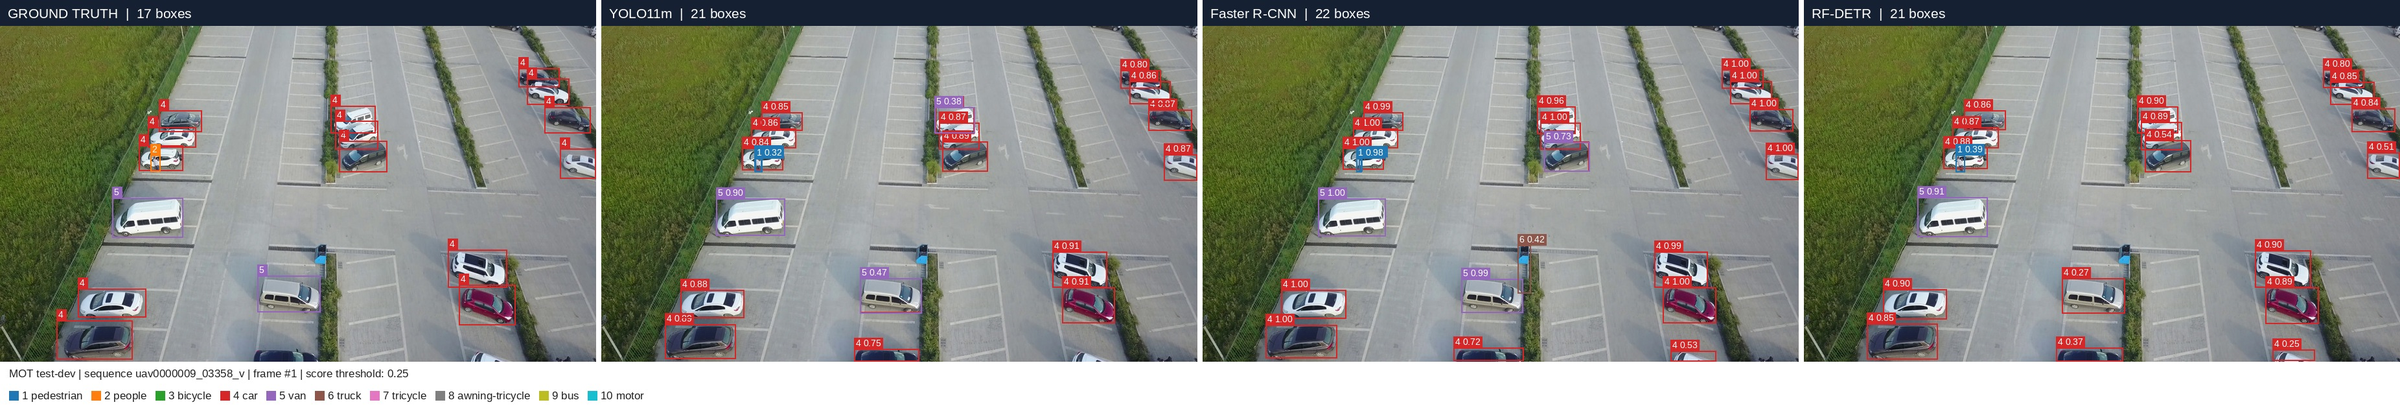


6 ảnh:
 - comparison_01_uav0000009_03358_v_frame0000001.jpg
 - comparison_02_uav0000009_03358_v_frame0000044.jpg
 - comparison_03_uav0000009_03358_v_frame0000088.jpg
 - comparison_04_uav0000009_03358_v_frame0000131.jpg
 - comparison_05_uav0000009_03358_v_frame0000175.jpg
 - comparison_06_uav0000009_03358_v_frame0000219.jpg


In [46]:
# Chỉ preview ảnh đầu
first = sorted(OUTPUT.glob('comparison_*.jpg'))[0]
with Image.open(first) as img:
    print('Full resolution:', img.size, '| file:', first.name)
    preview = img.copy()
    preview.thumbnail((2400, 2400), Image.Resampling.LANCZOS)
    display(preview)
print('\n6 ảnh:')
for p in sorted(OUTPUT.glob('comparison_*.jpg')):
    print(' -', p.name)